# Analiza braków danych · 2026

Sprawdzimy, w których pytaniach i rekordach brakuje odpowiedzi, które braki pojawiają się razem i jak kompletność zmienia się między grupami respondentów. Rok w tytule oznacza edycję notatnika. Datę zbierania danych trzeba potwierdzić w dokumentacji ankiety.

Najpierw tworzymy binarną maskę braków. Za brak uznajemy puste pola, dokładny znacznik `NA` oraz pola złożone wyłącznie z białych znaków. Zachowujemy odpowiedzi tekstowe takie jak `None`. **pandas** wczytuje dane i buduje maskę, **NumPy** wspiera obliczenia, **SciPy** grupuje podobne pytania, a **Seaborn** i **Matplotlib** pokazują wyniki.

W JupyterLab wybierz kernel `python3` ze środowiska projektu i użyj **Run All**, aby przeliczyć wyniki.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "requirements.txt").is_file() and (path / "notebooks").is_dir()),
    None,
)
if root is None:
    raise RuntimeError("Uruchom notatnik z katalogu repozytorium lub notebooks/.")

data_dir = root / "data" / "raw"
responses_path = data_dir / "survey_results_public.csv"
with responses_path.open("rb") as source:
    if source.readline(256).startswith(b"version https://git-lfs.github.com/spec/"):
        raise RuntimeError("Pobierz pełny CSV poleceniem git lfs pull.")

responses = pd.read_csv(
    responses_path, keep_default_na=False, na_values=["", "NA"], low_memory=False,
)
schema = pd.read_csv(data_dir / "survey_results_schema.csv")
if responses.empty:
    raise ValueError("Plik odpowiedzi nie zawiera rekordów.")

missing = responses.isna()
for column in responses.select_dtypes(include=["object", "string"]):
    whitespace = responses[column].astype("string").str.fullmatch(r"\s*", na=False)
    missing[column] |= whitespace.to_numpy(dtype=bool)

sns.set_theme(style="whitegrid")
print(f"Rekordy: {len(responses):,} | Kolumny: {responses.shape[1]}")

Rekordy: 30,903 | Kolumny: 212


## 1. Kompletność pytań po połączeniu macierzy według QID

Schemat wskazuje, które pola należą do macierzy. Łączymy je w jedną odpowiedź na pytanie dla każdego respondenta, zachowując nazwy podpunktów i ich zapisane wartości. Macierz ma zapis, jeśli co najmniej jeden jej podpunkt źródłowy jest wypełniony. Kolumny wyliczone jako część wspólna wyborów, np. `AIMemAdmired`, pozostają dostępne w surowych danych i kontroli schematu. Pokrycie pytania liczymy z wyborów źródłowych, od których zależą te kolumny.

Ranking pokazuje udział rekordów bez zapisu dla danego pola lub całego QID. Brak zapisu dla QID sam w sobie nie mówi, czy respondent widział pytanie, mógł niczego nie zaznaczyć albo je pominął. Sekcje 6 i 7 pokazują osobne mianowniki tam, gdzie można odtworzyć grupę z odpowiedzi. `AIDaily` analizujemy w sekcji 6.

Etykiety macierzy na wykresie opisują temat pytania. Identyfikatory QID są dostępne w tabelach.

,pytanie,pola eksportu,pola źródłowe,rekordy z zapisem,rekordy bez zapisu,bez zapisu_%
QID103,JobEaseAI,10,10,11973,18930,61.26
QID104,JobDifficultyAI,10,10,12246,18657,60.37
QID36,Languages,4,3,14099,16804,54.38
QID40,CodeTest,3,2,10604,20299,65.69
QID37,Databases,3,2,12061,18842,60.97
QID38,CloudPlat,3,2,10889,20014,64.76
QID39,WebFramework,3,2,10281,20622,66.73
QID41,DevIDE,3,2,13193,17710,57.31
QID42,CommPlat,3,2,10741,20162,65.24
QID44,LLM,4,3,11895,19008,61.51


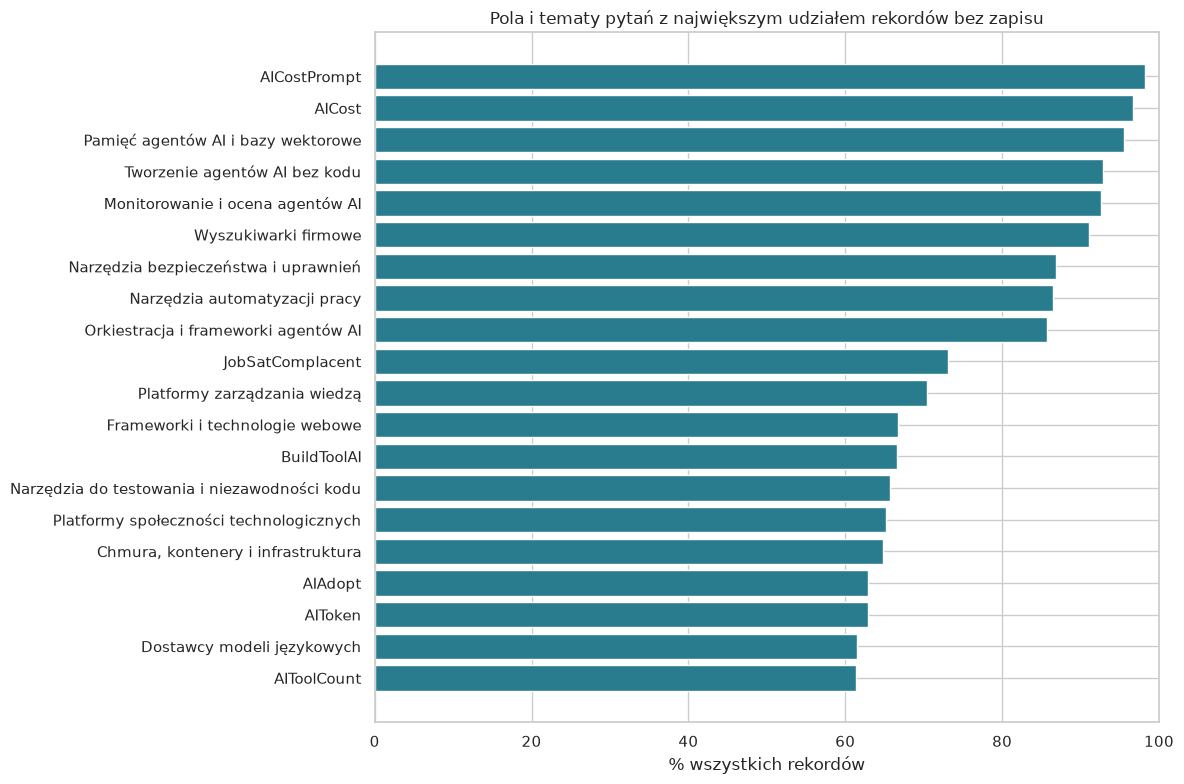

,puste,odpowiedzi,puste_%
AICostPrompt,30343,560,98.19
AICost,29870,1033,96.66
QID73,29511,1392,95.50
QID77,28684,2219,92.82
QID75,28626,2277,92.63
QID46,28157,2746,91.11
QID47,26851,4052,86.89
QID78,26730,4173,86.50
QID74,26503,4400,85.76
JobSatComplacent,22591,8312,73.10


In [2]:
job_factor_questions = ("JobEase", "JobDifficulty")
job_ai_prefixes = tuple(f"{question}AI_" for question in job_factor_questions)
matrix_prefixes = ("KnowledgeAcc_", "KnowledgeTime_", "KnowledgeSource_", "AIImpact_", "AISat_")
matrix_schema = schema.loc[schema["type"].str.strip().str.casefold().eq("matrix")]
matrix_groups = matrix_schema.groupby("qid", sort=False, dropna=False)
source_fields_by_qid = {}
merged_by_qid = {}
for qid, fields in matrix_groups:
    is_intersection = fields["transformation"].str.startswith("Intersection of", na=False)
    source_fields = fields.loc[~is_intersection, "column"].tolist()
    source_fields_by_qid[qid] = source_fields

    # Jedna odpowiedź na QID: pary (kolumna źródłowa, wartość) w kolejności schematu.
    values = responses[source_fields].mask(missing[source_fields]).stack().dropna()
    merged_by_qid[qid] = pd.Series({
        row: tuple(zip(group.index.get_level_values(1), group.to_numpy()))
        for row, group in values.groupby(level=0, sort=False)
    }, dtype=object)

matrix_answers = pd.DataFrame(merged_by_qid, index=responses.index)
matrix_missing = matrix_answers.isna()
analysis_mask = pd.concat([
    missing.drop(columns=matrix_schema["column"]),
    matrix_missing,
], axis=1)
ranked_mask = analysis_mask.drop(columns=["AIDaily"], errors="ignore")

matrix_coverage = pd.DataFrame({
    "pytanie": matrix_groups["qname"].first(),
    "pola eksportu": matrix_groups["column"].size(),
    "pola źródłowe": pd.Series({qid: len(fields) for qid, fields in source_fields_by_qid.items()}),
    "rekordy z zapisem": (~matrix_missing).sum(),
    "rekordy bez zapisu": matrix_missing.sum(),
    "bez zapisu_%": matrix_missing.mean().mul(100),
})
display(matrix_coverage.round(2))

field_summary = pd.DataFrame({
    "puste": ranked_mask.sum(),
    "odpowiedzi": (~ranked_mask).sum(),
    "puste_%": ranked_mask.mean().mul(100),
}).sort_values("puste_%", ascending=False, kind="stable")

question_topics = {
    "QID36": "Języki programowania i skryptowe",
    "QID37": "Bazy danych",
    "QID38": "Chmura, kontenery i infrastruktura",
    "QID39": "Frameworki i technologie webowe",
    "QID40": "Narzędzia do testowania i niezawodności kodu",
    "QID41": "Środowiska programistyczne i edytory",
    "QID42": "Platformy społeczności technologicznych",
    "QID44": "Dostawcy modeli językowych",
    "QID45": "Platformy zarządzania wiedzą",
    "QID46": "Wyszukiwarki firmowe",
    "QID47": "Narzędzia bezpieczeństwa i uprawnień",
    "QID66": "AI w procesie pracy",
    "QID70": "Użyteczność AI przy zadaniach",
    "QID71": "Wpływ AI na satysfakcję z zadań",
    "QID73": "Pamięć agentów AI i bazy wektorowe",
    "QID74": "Orkiestracja i frameworki agentów AI",
    "QID75": "Monitorowanie i ocena agentów AI",
    "QID76": "Agenci i asystenci do programowania",
    "QID77": "Tworzenie agentów AI bez kodu",
    "QID78": "Narzędzia automatyzacji pracy",
    "QID87": "Dokładność informacji ze źródeł",
    "QID88": "Aktualność informacji ze źródeł",
    "QID89": "Możliwość sprawdzenia źródła informacji",
    "QID103": "Rola AI w ułatwianiu pracy",
    "QID104": "Rola AI w utrudnianiu pracy",
    "QID107": "Częstotliwość używania narzędzi AI",
}
schema_questions = matrix_groups["question"].first()

fig, ax = plt.subplots(figsize=(12, 8))
top_fields = field_summary.head(20).iloc[::-1]
labels = [
    question_topics.get(field, schema_questions.get(field, field))
    for field in top_fields.index
]
ax.barh(labels, top_fields["puste_%"], color="#287c8e")
ax.set(xlim=(0, 100), xlabel="% wszystkich rekordów", title="Pola i tematy pytań z największym udziałem rekordów bez zapisu")
plt.tight_layout()
plt.show()

with pd.option_context("display.max_rows", len(field_summary)):
    display(field_summary.round(2))

## 2. Czy liczba odpowiedzi zgadza się ze słownikiem danych?

Porównujemy własne liczniki z polem `nonmissing` w słowniku. Raportujemy osobno pola obecne tylko w jednym pliku i pola wspólne z rozbieżnymi licznikami. Różnica może wynikać m.in. z reguł liczenia białych znaków lub z wersji eksportu. Nie zmieniamy plików wejściowych.

In [3]:
schema_counts = pd.to_numeric(schema.set_index("column")["nonmissing"], errors="coerce")
observed = (~missing).sum()
only_data = observed.index.difference(schema_counts.index)
only_schema = schema_counts.index.difference(observed.index)
unchecked = schema_counts[schema_counts.isna()].index.intersection(observed.index)
comparison = pd.concat(
    [observed.rename("w CSV"), schema_counts.rename("w słowniku")], axis=1, join="inner",
).dropna()
comparison["różnica"] = comparison["w CSV"] - comparison["w słowniku"]
differences = comparison.loc[comparison["różnica"].ne(0)]
print(f"Tylko w CSV: {len(only_data)} {only_data.tolist()}")
print(f"Tylko w słowniku: {len(only_schema)} {only_schema.tolist()}")
print(f"Wspólne pola bez licznika w słowniku: {len(unchecked)} {unchecked.tolist()}")
print(f"Rozbieżne liczniki: {len(differences)} z {len(comparison)} porównanych pól")
display(differences.loc[differences["różnica"].abs().sort_values(ascending=False).index].head(20))

Tylko w CSV: 0 []
Tylko w słowniku: 0 []
Wspólne pola bez licznika w słowniku: 0 []
Rozbieżne liczniki: 0 z 212 porównanych pól


,w CSV,w słowniku,różnica


## 3. Ile braków przypada na jeden rekord?

Histogram pokazuje rozkład odsetka braków w rekordzie, a tabela podaje jego kwartyle i 90. percentyl. Dodatkowo liczymy najczęstsze identyczne wzorce obecności i braku odpowiedzi dla kolumn analitycznych po połączeniu macierzy według QID. Pokazujemy tylko liczebności wzorców, bez odpowiedzi i identyfikatorów.

Każda macierz liczy się jako jedna pozycja. Mianownik obejmuje także pytania warunkowe, więc wykres opisuje pokrycie zapisem w eksporcie.

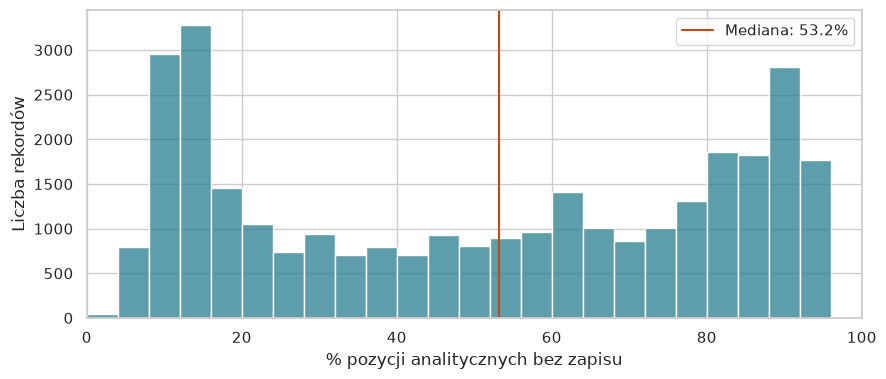

,braki_%
0.25,18.09
0.50,53.19
0.75,80.85
0.90,89.36


,liczba rekordów,odsetek rekordów,pozycje bez zapisu we wzorcu
pozycja,,,
1,994,3.22,89
2,561,1.82,85
3,541,1.75,84
4,443,1.43,76
5,435,1.41,75
6,406,1.31,83
7,285,0.92,76
8,268,0.87,77


In [4]:
row_rates = analysis_mask.mean(axis=1).mul(100)
packed = np.packbits(analysis_mask.to_numpy(dtype=bool), axis=1)
pattern_counts = pd.Series([row.tobytes() for row in packed], dtype=object).value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(row_rates, bins=np.linspace(0, 100, 26), color="#287c8e", ax=ax)
ax.axvline(row_rates.median(), color="#c24914", label=f"Mediana: {row_rates.median():.1f}%")
ax.set(xlim=(0, 100), xlabel="% pozycji analitycznych bez zapisu", ylabel="Liczba rekordów")
ax.legend()
plt.show()

display(row_rates.quantile([0.25, 0.5, 0.75, 0.9]).rename("braki_%").to_frame().round(2))
top_patterns = pattern_counts.head(8)
display(pd.DataFrame({
    "liczba rekordów": top_patterns.to_numpy(),
    "odsetek rekordów": (100 * top_patterns / len(responses)).round(2).to_numpy(),
    "pozycje bez zapisu we wzorcu": [sum(byte.bit_count() for byte in pattern) for pattern in top_patterns.index],
}, index=pd.RangeIndex(1, len(top_patterns) + 1, name="pozycja")))

## 4. Które pytania mają wspólne braki?

Na mapie pokazujemy korelację **phi**, czyli korelację Pearsona dwóch masek zero-jedynkowych. Wartości dodatnie oznaczają, że braki częściej występują razem, a ujemne wskazują przeciwne wzorce. Wybieramy do 24 pól o największej zmienności maski, czyli z udziałem braków najbliższym 50%. SciPy porządkuje pola według podobieństwa na podstawie odległości `1 − phi`. Wspólny wzorzec może podpowiadać, gdzie szukać wspólnego filtra ankiety.

Każdą macierz traktujemy jako jeden QID. Korelacja dotyczy współwystępowania zapisów na poziomie pytań, z uwzględnieniem ich warunkowego charakteru.

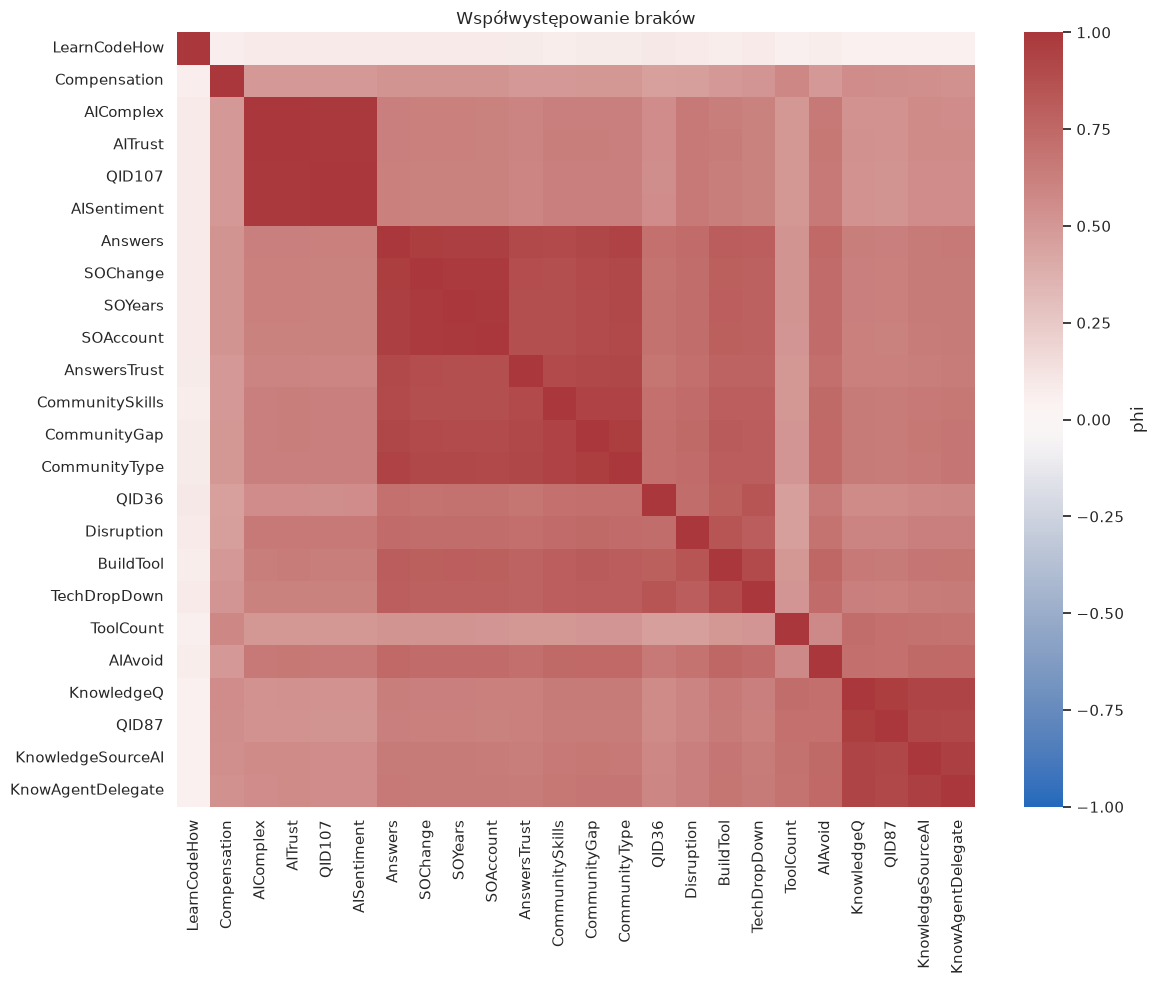

phi
AIComplex   AITrust      0.994
QID107      AISentiment  0.992
AISentiment AIComplex    0.991
SOYears     SOAccount    0.989
AISentiment AITrust      0.989
QID107      AIComplex    0.987
            AITrust      0.985
SOChange    SOYears      0.981

In [5]:
rates = analysis_mask.mean()
variable_rates = rates[rates.between(0, 1, inclusive="neither")]
selected = (variable_rates - 0.5).abs().nsmallest(24).index
if len(selected) >= 2:
    phi = analysis_mask[selected].astype(float).corr()
    distance = np.clip(1 - phi.to_numpy(), 0, 2)
    distance = (distance + distance.T) / 2
    np.fill_diagonal(distance, 0)
    order = leaves_list(linkage(squareform(distance), method="average"))
    ordered_phi = phi.iloc[order, order]

    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(ordered_phi, vmin=-1, vmax=1, center=0,
                cmap="vlag", cbar_kws={"label": "phi"}, ax=ax)
    ax.set_title("Współwystępowanie braków")
    plt.tight_layout()
    plt.show()

    upper = np.triu(np.ones(phi.shape, dtype=bool), k=1)
    pair_values = phi.where(upper).stack()
    display(pair_values.nlargest(8).rename("phi").to_frame().round(3))
else:
    print("Do porównania potrzeba co najmniej dwóch pól o zmiennym wzorcu braków.")

## 5. Jak odpowiedź na jedno pytanie wiąże się z kompletnością kolejnych?

Dla kategorii odpowiedzi na `AISelect` i `Employment` liczymy odsetek braków w powiązanych pytaniach. Pokazujemy grupy liczące co najmniej 100 rekordów, a podstawą każdego odsetka jest liczebność danej grupy. Osobno oznaczamy rekordy z brakiem w pytaniu grupującym. Wyniki mogą pomóc odnaleźć pytania warunkowe, których reguły trzeba sprawdzić w formularzu.

/tmp/ipykernel_6378/891789104.py:23: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


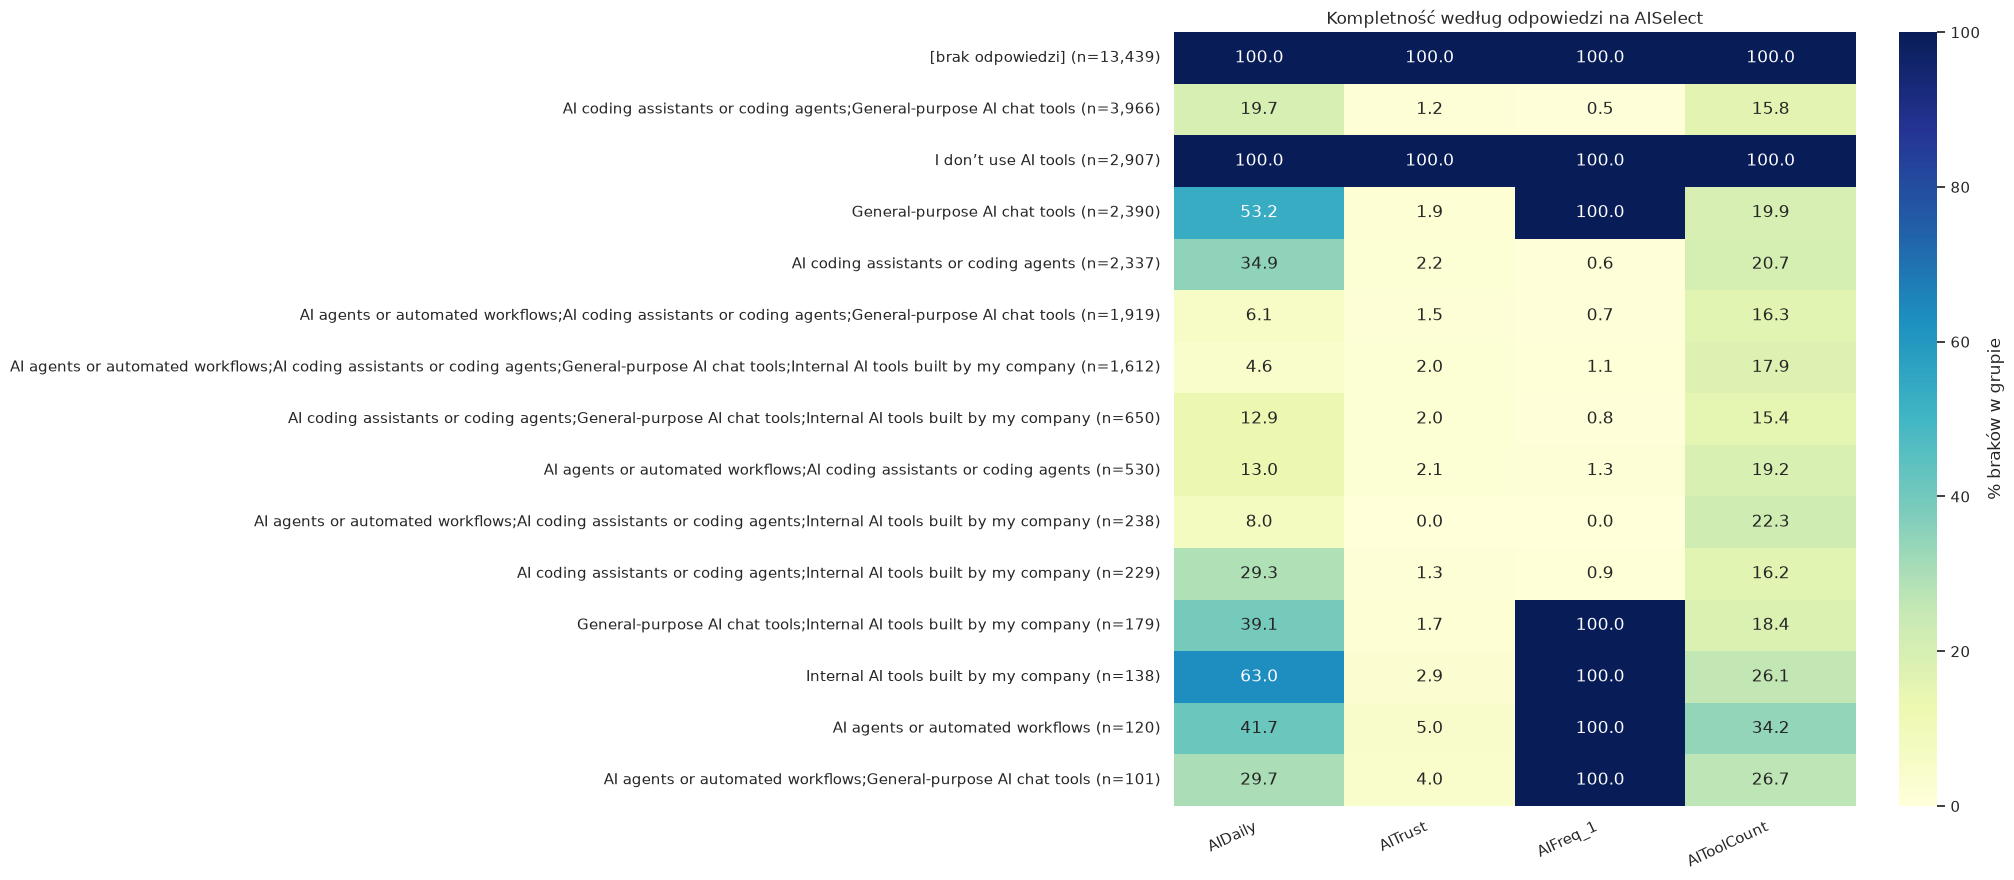

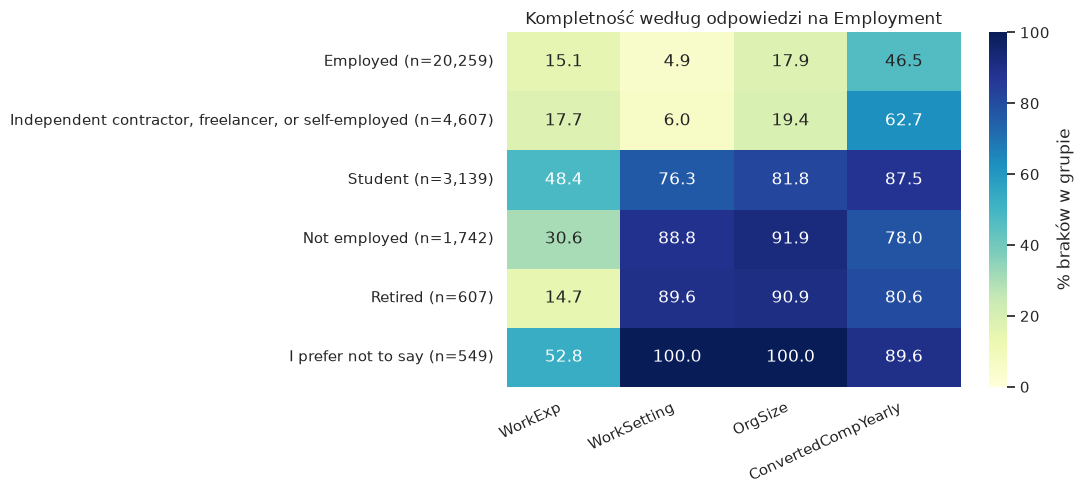

In [6]:
group_checks = {
    "AISelect": ["AIDaily", "AITrust", "AIFreq_1", "AIToolCount"],
    "Employment": ["WorkExp", "WorkSetting", "OrgSize", "ConvertedCompYearly"],
}
for group_field, outcomes in group_checks.items():
    outcomes = [field for field in outcomes if field in missing]
    if group_field not in responses or not outcomes:
        continue
    groups = responses[group_field].astype("string").mask(missing[group_field], "[brak odpowiedzi]")
    sizes = groups.value_counts()
    eligible = sizes[sizes.ge(100)]
    if eligible.empty:
        print(f"{group_field}: brak grup z co najmniej 100 rekordami.")
        continue

    group_rates = missing[outcomes].groupby(groups).mean().loc[eligible.index].mul(100)
    group_rates.index = [f"{label} (n={size:,})" for label, size in eligible.items()]
    fig, ax = plt.subplots(figsize=(11, max(2.5, 0.55 * len(group_rates) + 1.8)))
    sns.heatmap(group_rates, annot=True, fmt=".1f", vmin=0, vmax=100,
                cmap="YlGnBu", cbar_kws={"label": "% braków w grupie"}, ax=ax)
    ax.set(ylabel="", title=f"Kompletność według odpowiedzi na {group_field}")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## 6. Co oznacza wysoki odsetek braków w konkretnym pytaniu?

Słownik opisuje `AIDaily` jako pytanie dla osób deklarujących codzienne użycie AI. Porównujemy odsetek braków w całym eksporcie z odsetkiem wśród osób, które wybrały `Daily` przynajmniej raz w polach `AIFreq_1`–`AIFreq_4`. To grupa zrekonstruowana z odpowiedzi. Bez logów formularza nie wiemy, komu faktycznie wyświetlono pytanie.

`JobEase` i `JobDifficulty` zawierają po jednym wyborze czynnika, który odpowiednio ułatwił lub utrudnił pracę. Bloki `JobEaseAI` i `JobDifficultyAI` zapisują odpowiedź uzupełniającą o roli AI dla wybranego czynnika. Dla każdego podpunktu łączymy etykietę ze słownika z wyborem w odpowiednim pytaniu głównym i osobno liczymy zapisy w pasującej grupie oraz poza nią. Puste komórki poza pasującą grupą są zgodne ze strukturą pytania warunkowego. Brak zapisu w pasującej grupie wymaga sprawdzenia reguł formularza lub eksportu przed uznaniem go za pominiętą odpowiedź.


In [7]:
daily = responses[[f"AIFreq_{i}" for i in range(1, 5)]].eq("Daily").any(axis=1)
daily_bases = {
    "Cały eksport": missing["AIDaily"],
    "Co najmniej jedno Daily": missing.loc[daily, "AIDaily"],
    "Brak deklaracji Daily w AIFreq": missing.loc[~daily, "AIDaily"],
}
display(pd.DataFrame.from_dict({
    label: {"rekordy": len(mask), "odpowiedzi": int((~mask).sum()),
            "braki": int(mask.sum()), "braki_%": mask.mean() * 100}
    for label, mask in daily_bases.items()
}, orient="index").round(2))

raw_fields = ["JobEaseAI_7", "JobDifficultyAI_8"]
raw_subquestions = pd.read_csv(
    responses_path, usecols=raw_fields, dtype=str, na_filter=False,
)
display(raw_subquestions.apply(pd.Series.value_counts).fillna(0).astype(int))
display(schema_counts.loc[raw_fields].rename("odpowiedzi według słownika").to_frame())

for question, prefix in zip(job_factor_questions, job_ai_prefixes, strict=True):
    rows = []
    for item in schema.loc[schema["column"].str.startswith(prefix)].itertuples(index=False):
        selected_factor = responses[question].eq(item.sub).fillna(False)
        recorded = ~missing[item.column]
        rows.append({
            "pole": item.column,
            "czynnik": item.sub,
            "wybrali czynnik": int(selected_factor.sum()),
            "zapis w pasującej grupie": int((selected_factor & recorded).sum()),
            "puste w pasującej grupie": int((selected_factor & ~recorded).sum()),
            "zapis poza grupą": int((~selected_factor & recorded).sum()),
        })
    summary = pd.DataFrame(rows).set_index("pole")
    base = summary["wybrali czynnik"]
    summary["puste w pasującej grupie_%"] = (
        summary["puste w pasującej grupie"].div(base.where(base.gt(0))).mul(100)
    )
    display(Markdown(f"### {question}"))
    display(summary.round(2))
    print("Maksymalna liczba zapisanych podpunktów na rekord:",
          int((~missing.loc[:, missing.columns.str.startswith(prefix)]).sum(axis=1).max()))

,rekordy,odpowiedzi,braki,braki_%
Cały eksport,30903,10926,19977,64.64
Co najmniej jedno Daily,10982,10926,56,0.51
Brak deklaracji Daily w AIFreq,19921,0,19921,100.00


,JobEaseAI_7,JobDifficultyAI_8
NA,30903,30903


,odpowiedzi według słownika
column,
JobEaseAI_7,0
JobDifficultyAI_8,0


### JobEase

,czynnik,wybrali czynnik,zapis w pasującej grupie,puste w pasującej grupie,zapis poza grupą,puste w pasującej grupie_%
pole,,,,,,
JobEaseAI_1,Clear priorities or requirements,1314,1307,7,0,0.53
JobEaseAI_2,Access to the right tools or platforms,3714,3688,26,0,0.70
JobEaseAI_3,"Reliable systems, infrastructure, or environments",741,735,6,0,0.81
JobEaseAI_4,Helpful documentation or knowledge sharing,768,759,9,0,1.17
JobEaseAI_5,"Supportive teammates, managers, or mentors",3191,3164,27,0,0.85
JobEaseAI_6,"Enough time, staffing, or resources",1088,1078,10,0,0.92
JobEaseAI_7,Leadership activity or organizational changes,396,0,396,0,100.00
JobEaseAI_8,"Better processes, workflows, or coordination",1256,1242,14,0,1.11
JobEaseAI_9,Nothing has made my job easier in the past 6 m...,3902,0,3902,0,100.00


Maksymalna liczba zapisanych podpunktów na rekord: 1


### JobDifficulty

,czynnik,wybrali czynnik,zapis w pasującej grupie,puste w pasującej grupie,zapis poza grupą,puste w pasującej grupie_%
pole,,,,,,
JobDifficultyAI_1,Unclear priorities or requirements,3029,3009,20,0,0.66
JobDifficultyAI_2,Lack of access to the right tools or platforms,507,499,8,0,1.58
JobDifficultyAI_3,"Unreliable systems, infrastructure, or environ...",1523,1514,9,0,0.59
JobDifficultyAI_4,Poor documentation or knowledge sharing,1292,1283,9,0,0.70
JobDifficultyAI_5,"Lack of support from teammates, managers, or m...",761,749,12,0,1.58
JobDifficultyAI_6,"Not enough time, staffing, or resources",2566,2554,12,0,0.47
JobDifficultyAI_7,"Inefficient processes, workflows, or coordination",2658,2638,20,0,0.75
JobDifficultyAI_8,Leadership activity or organizational changes,2162,0,2162,0,100.00
JobDifficultyAI_9,Nothing has made my job harder in the past 6 m...,1743,0,1743,0,100.00


Maksymalna liczba zapisanych podpunktów na rekord: 1


## 7. Źródła wiedzy i zastosowania AI

**Źródła wiedzy.** W `KnowledgeQ` można wybrać do pięciu źródeł. Dla każdego podpunktu `KnowledgeAcc`, `KnowledgeTime` i `KnowledgeSource` bierzemy dokładną etykietę źródła ze słownika i liczymy puste pola wśród osób, które je wybrały. Osobno zliczamy odpowiedzi poza dobraną grupą, co pozwala wykryć niespójność założenia z danymi.

**Zastosowania AI.** `AIImpact` mierzy użyteczność, a `AISat` zmianę satysfakcji z wykonania zadania. Grupą odniesienia są osoby, które w `AISelect` wskazały co najmniej jedno narzędzie lub zastosowanie AI. To przybliżenie: deklaracja użycia AI w pracy nie określa, czy respondent korzystał z niego przy danym zadaniu ani czy widział każdy podpunkt. Jawne odpowiedzi `Not applicable` liczymy osobno jako zapisane odpowiedzi. Odsetek pustych w tej grupie to wskaźnik pokrycia zapisem, którego nie należy utożsamiać z odsetkiem pominiętych odpowiedzi.

In [8]:
def selection_masks(column):
    selections = responses.loc[~missing[column], column].str.split(";").explode().str.strip()
    return {
        label: pd.Series(responses.index.isin(group.index), index=responses.index)
        for label, group in selections.groupby(selections, sort=False)
    }

knowledge_choices = selection_masks("KnowledgeQ")
ai_choices = selection_masks("AISelect")
uses_ai = pd.DataFrame({
    label: chosen for label, chosen in ai_choices.items() if label != "I don’t use AI tools"
}, index=responses.index).any(axis=1)
unselected = pd.Series(False, index=responses.index)
rows = []
for item in schema.loc[schema["column"].str.startswith(matrix_prefixes)].itertuples(index=False):
    knowledge = item.column.startswith("Knowledge")
    reference_group = knowledge_choices.get(item.sub, unselected) if knowledge else uses_ai
    recorded = ~missing[item.column]
    rows.append({
        "pole": item.column,
        "podpunkt": item.sub,
        "puste w CSV": int((~recorded).sum()),
        "liczebność grupy": int(reference_group.sum()),
        "puste w grupie": int((reference_group & ~recorded).sum()),
        "jawne Not applicable w grupie": int(
            (reference_group & responses[item.column].eq("Not applicable").fillna(False)).sum()
        ),
        "zapis poza grupą": int((~reference_group & recorded).sum()),
    })
matrix_summary = pd.DataFrame(rows).set_index("pole")
group_size = matrix_summary["liczebność grupy"]
matrix_summary["puste w grupie_%"] = (
    matrix_summary["puste w grupie"].div(group_size.where(group_size.gt(0))).mul(100)
)
examples = ["KnowledgeSource_3", "KnowledgeTime_8", "KnowledgeAcc_6", "AISat_1", "AIImpact_2"]
display(matrix_summary.loc[examples].round(2))
with pd.option_context("display.max_rows", len(matrix_summary)):
    display(matrix_summary.round(2))

,podpunkt,puste w CSV,liczebność grupy,puste w grupie,jawne Not applicable w grupie,zapis poza grupą,puste w grupie_%
pole,,,,,,,
KnowledgeSource_3,"Internal documentation (i.e. Design, product, ...",22978,8687,762,0,0,8.77
KnowledgeTime_8,Meeting notes or transcripts,29445,1536,78,0,0,5.08
KnowledgeAcc_6,Code repositories or code comments,22086,9065,248,0,0,2.74
AISat_1,Design,19135,14557,2789,0,0,19.16
AIImpact_2,Implementation,18357,14557,2011,494,0,13.81


,podpunkt,puste w CSV,liczebność grupy,puste w grupie,jawne Not applicable w grupie,zapis poza grupą,puste w grupie_%
pole,,,,,,,
AIImpact_1,Design,18367,14557,2021,2151,0,13.88
AIImpact_2,Implementation,18357,14557,2011,494,0,13.81
AIImpact_3,Review,18454,14557,2108,1242,0,14.48
AIImpact_4,Debugging/refactoring,18375,14557,2029,604,0,13.94
AIImpact_5,Documentation,18420,14557,2074,1258,0,14.25
AIImpact_6,Architecture exploration,18475,14557,2129,1563,0,14.63
AIImpact_7,Communication,18489,14557,2143,2337,0,14.72
AISat_1,Design,19135,14557,2789,0,0,19.16
AISat_2,Implementation,18982,14557,2636,0,0,18.11


## 8. Wnioski z bieżącego uruchomienia

Podsumowanie aktualizuje się po zmianie danych. Liczby dla całego eksportu opisują puste komórki, także te wynikające ze struktury ankiety. Dla pytań warunkowych z sekcji 6 i 7 czytaj wyniki w odniesieniu do wskazanej tam grupy.

W podsumowaniu każda macierz liczy się raz, zgodnie z QID.

In [9]:
display(Markdown(
    f"- Po połączeniu macierzy **{analysis_mask.to_numpy().mean():.1%}** pozycji analitycznych nie ma zapisu. "
    f"Mediana udziału pozycji bez zapisu w rekordzie wynosi **{row_rates.median():.1f}%**.\n"
    f"- W danych występuje **{len(pattern_counts):,}** różnych wzorców braków. "
    f"Najczęstszy obejmuje **{pattern_counts.iloc[0]:,}** rekordów.\n"
    f"- Liczniki CSV i słownika różnią się w **{len(differences)}** "
    f"z **{len(comparison)}** porównanych pól."
))

- Po połączeniu macierzy **50.7%** pozycji analitycznych nie ma zapisu. Mediana udziału pozycji bez zapisu w rekordzie wynosi **53.2%**.
- W danych występuje **19,541** różnych wzorców braków. Najczęstszy obejmuje **994** rekordów.
- Liczniki CSV i słownika różnią się w **0** z **212** porównanych pól.